In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
!git clone https://github.com/yuval-alaluf/SAM.git
%cd SAM

Cloning into 'SAM'...
remote: Enumerating objects: 228, done.
remote: Counting objects: 100% (48/48), done.
remote: Compressing objects: 100% (26/26), done.
remote: Total 228 (delta 32), reused 22 (delta 22), pack-reused 180 (from 1)
Receiving objects: 100% (228/228), 24.63 MiB | 40.55 MiB/s, done.
Resolving deltas: 100% (78/78), done.
/content/SAM


In [ ]:
%cd /content/SAM

!ls environment
!cat environment/sam_env.yaml


/content/SAM
sam_env.yaml
name: sam_env
channels:
  - conda-forge
  - defaults
dependencies:
  - _libgcc_mutex=0.1=main
  - ca-certificates=2020.4.5.1=hecc5488_0
  - certifi=2020.4.5.1=py36h9f0ad1d_0
  - libedit=3.1.20181209=hc058e9b_0
  - libffi=3.2.1=hd88cf55_4
  - libgcc-ng=9.1.0=hdf63c60_0
  - libstdcxx-ng=9.1.0=hdf63c60_0
  - ncurses=6.2=he6710b0_1
  - ninja=1.10.0=hc9558a2_0
  - openssl=1.1.1g=h516909a_0
  - pip=20.0.2=py36_3
  - python=3.6.7=h0371630_0
  - python_abi=3.6=1_cp36m
  - readline=7.0=h7b6447c_5
  - setuptools=46.4.0=py36_0
  - sqlite=3.31.1=h62c20be_1
  - tk=8.6.8=hbc83047_0
  - wheel=0.34.2=py36_0
  - xz=5.2.5=h7b6447c_0
  - zlib=1.2.11=h7b6447c_3
  - pip:
    - scipy==1.4.1
    - matplotlib==3.2.1
    - tqdm==4.46.0
    - numpy==1.18.4
    - opencv-python==4.2.0.34
    - pillow==7.1.2
    - tensorboard==2.2.1
    - torch==1.6.0
    - torchvision==0.4.2
prefix: ~/anaconda3/envs/sam_env

In [ ]:
import torchvision
import numpy
import scipy
import PIL

print("Torchvision:", torchvision.__version__)
print("NumPy:", numpy.__version__)
print("SciPy:", scipy.__version__)
print("Pillow:", PIL.__version__)

Torchvision: 0.26.0+cu130
NumPy: 2.1.3
SciPy: 1.16.3
Pillow: 11.3.0


In [ ]:
!nvidia-smi


Sat Oct 31 05:55:17 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
%cd /content/SAM

!find . -maxdepth 3 -type f | sort | head -100

/content/SAM
./cog.yaml
./configs/data_configs.py
./configs/__init__.py
./configs/paths_config.py
./configs/transforms_config.py
./criteria/aging_loss.py
./criteria/id_loss.py
./criteria/__init__.py
./criteria/lpips/__init__.py
./criteria/lpips/lpips.py
./criteria/lpips/networks.py
./criteria/lpips/utils.py
./criteria/w_norm.py
./datasets/augmentations.py
./datasets/images_dataset.py
./datasets/inference_dataset.py
./datasets/__init__.py
./docs/1005_style_mixing.jpg
./docs/1936.jpg
./docs/2195.jpg
./docs/866.jpg
./docs/teaser.jpeg
./environment/sam_env.yaml
./.git/config
./.git/description
./.git/HEAD
./.git/hooks/applypatch-msg.sample
./.git/hooks/commit-msg.sample
./.git/hooks/fsmonitor-watchman.sample
./.git/hooks/post-update.sample
./.git/hooks/pre-applypatch.sample
./.git/hooks/pre-commit.sample
./.git/hooks/pre-merge-commit.sample
./.git/hooks/prepare-commit-msg.sample
./.git/hooks/pre-push.sample
./.git/hooks/pre-rebase.sample
./.git/hooks/pre-receive.sample
./.git/hooks/push-to

In [ ]:
!find . -type f \( -name "*.cu" -o -name "*.cpp" -o -name "setup.py" \)
import sys
print("Python version:", sys.version)

./models/stylegan2/op/upfirdn2d.cpp
./models/stylegan2/op/upfirdn2d_kernel.cu
./models/stylegan2/op/fused_bias_act.cpp
./models/stylegan2/op/fused_bias_act_kernel.cu
Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


In [ ]:
%cd /content/SAM

!sed -n '1,240p' models/stylegan2/op/fused_act.py
!sed -n '1,260p' models/stylegan2/op/upfirdn2d.py
import torch
from torch.utils.cpp_extension import CUDA_HOME
import shutil

print("PyTorch:", torch.__version__)
print("CUDA runtime:", torch.version.cuda)
print("CUDA_HOME:", CUDA_HOME)
print("NVCC:", shutil.which("nvcc"))

/content/SAM
import os

import torch
from torch import nn
from torch.autograd import Function
from torch.utils.cpp_extension import load

module_path = os.path.dirname(__file__)
fused = load(
    'fused',
    sources=[
        os.path.join(module_path, 'fused_bias_act.cpp'),
        os.path.join(module_path, 'fused_bias_act_kernel.cu'),
    ],
)


class FusedLeakyReLUFunctionBackward(Function):
    @staticmethod
    def forward(ctx, grad_output, out, negative_slope, scale):
        ctx.save_for_backward(out)
        ctx.negative_slope = negative_slope
        ctx.scale = scale

        empty = grad_output.new_empty(0)

        grad_input = fused.fused_bias_act(
            grad_output, empty, out, 3, 1, negative_slope, scale
        )

        dim = [0]

        if grad_input.ndim > 2:
            dim += list(range(2, grad_input.ndim))

        grad_bias = grad_input.sum(dim).detach()

        return grad_input, grad_bias

    @staticmethod
    def backward(ctx, gradgrad_input, gradgra

In [ ]:
!nvcc --version
!g++ --version
!ninja --version
import torch

print("GPU capability:", torch.cuda.get_device_capability(0))
print("GPU name:", torch.cuda.get_device_name(0))
print("PyTorch CUDA architectures:", torch.cuda.get_arch_list())

%cd /content/SAM

!sed -n '1,220p' models/stylegan2/op/fused_bias_act.cpp
!sed -n '1,220p' models/stylegan2/op/upfirdn2d.cpp

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2025 NVIDIA Corporation
Built on Wed_Aug_20_01:58:59_PM_PDT_2025
Cuda compilation tools, release 13.0, V13.0.88
Build cuda_13.0.r13.0/compiler.36424714_0
g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
Copyright (C) 2023 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.

/bin/bash: line 1: ninja: command not found
GPU capability: (7, 5)
GPU name: Tesla T4
PyTorch CUDA architectures: ['sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120']
/content/SAM
#include <torch/extension.h>


torch::Tensor fused_bias_act_op(const torch::Tensor& input, const torch::Tensor& bias, const torch::Tensor& refer,
    int act, int grad, float alpha, float scale);

#define CHECK_CUDA(x) TORCH_CHECK(x.type().is_cuda(), #x " must be a CUDA tensor")
#define CHECK_CONTIGUOUS(x) TORCH_CHECK(x.is_contiguous(), #x " must be contigu

In [ ]:
!pip install ninja
import os
import torch

os.environ["TORCH_CUDA_ARCH_LIST"] = "7.5"

%cd /content/SAM

from models.stylegan2.op.fused_act import fused_leaky_relu

x = torch.randn(2, 8, 16, 16, device="cuda")
bias = torch.zeros(8, device="cuda")

y = fused_leaky_relu(x, bias)

print("Input shape:", x.shape)
print("Output shape:", y.shape)
print("Output device:", y.device)
print("Compilation and test successful!")
!ninja --version

/content/SAM
Input shape: torch.Size([2, 8, 16, 16])
Output shape: torch.Size([2, 8, 16, 16])
Output device: cuda:0
Compilation and test successful!
1.13.2.git.kitware.jobserver-pipe-1


In [ ]:
import torch
import os

os.environ["TORCH_CUDA_ARCH_LIST"] = "7.5"

%cd /content/SAM

from models.stylegan2.op.upfirdn2d import upfirdn2d

# Create a sample GPU image
x = torch.randn(1, 3, 16, 16, device="cuda")

# Create a simple blur kernel
kernel = torch.tensor(
    [[1., 2., 1.],
     [2., 4., 2.],
     [1., 2., 1.]],
    device="cuda"
)

kernel = kernel / kernel.sum()

# Run the operation
y = upfirdn2d(x, kernel, up=1, down=1, pad=(1, 1))

print("Input shape:", x.shape)
print("Output shape:", y.shape)
print("Output device:", y.device)
print("Output contains NaN:", torch.isnan(y).any().item())
print("upfirdn2d test successful!")

/content/SAM
Input shape: torch.Size([1, 3, 16, 16])
Output shape: torch.Size([1, 3, 16, 16])
Output device: cuda:0
Output contains NaN: False
upfirdn2d test successful!


In [ ]:
import importlib

packages = [
    "numpy",
    "scipy",
    "matplotlib",
    "tqdm",
    "cv2",
    "PIL",
    "dlib",
    "tensorboard",
    "gdown",
    "lpips"
]

for package in packages:
    try:
        module = importlib.import_module(package)
        version = getattr(module, "__version__", "Available")
        print(f"{package}: {version}")
    except Exception as e:
        print(f"{package}: NOT AVAILABLE ({type(e).__name__})")
%cd /content/SAM

!sed -n '1,220p' scripts/inference.py
!sed -n '1,220p' configs/paths_config.py

numpy: 2.1.3
scipy: 1.16.3
matplotlib: 3.10.0
tqdm: 4.67.3
cv2: 4.14.0
PIL: 11.3.0
dlib: 20.0.1
tensorboard: 2.21.0
gdown: 5.2.2
lpips: NOT AVAILABLE (ModuleNotFoundError)
/content/SAM
from argparse import Namespace
import os
import time
from tqdm import tqdm
from PIL import Image
import numpy as np
import torch
from torch.utils.data import DataLoader

import sys
sys.path.append(".")
sys.path.append("..")

from configs import data_configs
from datasets.inference_dataset import InferenceDataset
from datasets.augmentations import AgeTransformer
from utils.common import tensor2im, log_image
from options.test_options import TestOptions
from models.psp import pSp


def run():
	test_opts = TestOptions().parse()

	out_path_results = os.path.join(test_opts.exp_dir, 'inference_results')
	out_path_coupled = os.path.join(test_opts.exp_dir, 'inference_coupled')
	os.makedirs(out_path_results, exist_ok=True)
	os.makedirs(out_path_coupled, exist_ok=True)

	# update test options with options used duri

In [ ]:
!pip install lpips
import lpips
print("LPIPS installed successfully")
%cd /content/SAM

!sed -n '1,260p' models/psp.py
!grep -n -i -E "checkpoint|pretrained|download|inference|google drive" README.md

LPIPS installed successfully
/content/SAM
"""
This file defines the core research contribution
"""
import copy
from argparse import Namespace

import torch
from torch import nn
import math

from configs.paths_config import model_paths
from models.encoders import psp_encoders
from models.stylegan2.model import Generator


class pSp(nn.Module):

	def __init__(self, opts):
		super(pSp, self).__init__()
		self.set_opts(opts)
		self.n_styles = int(math.log(self.opts.output_size, 2)) * 2 - 2
		# Define architecture
		self.encoder = self.set_encoder()
		self.decoder = Generator(self.opts.output_size, 512, 8)
		self.face_pool = torch.nn.AdaptiveAvgPool2d((256, 256))
		# Load weights if needed
		self.load_weights()

	def set_encoder(self):
		return psp_encoders.GradualStyleEncoder(50, 'ir_se', self.n_styles, self.opts)

	def load_weights(self):
		if self.opts.checkpoint_path is not None:
			print(f'Loading SAM from checkpoint: {self.opts.checkpoint_path}')
			ckpt = torch.load(self.opts.checkpo

In [ ]:
%cd /content/SAM

!mkdir -p pretrained_models

!gdown "https://drive.google.com/uc?id=1XyumF6_fdAxFmxpFcmPf-q84LU_22EMC" \
    -O pretrained_models/sam_ffhq_aging.pt
import os

checkpoint = "pretrained_models/sam_ffhq_aging.pt"

if os.path.exists(checkpoint):
    print("Checkpoint downloaded successfully!")
    print("File size:", round(os.path.getsize(checkpoint) / (1024**3), 2), "GB")
else:
    print("Checkpoint not found. Please share the download error.")
import torch

checkpoint_data = torch.load(
    "pretrained_models/sam_ffhq_aging.pt",
    map_location="cpu",
    weights_only=False
)

print("Checkpoint keys:", checkpoint_data.keys())
print("Saved options:", checkpoint_data.get("opts", {}).keys())

/content/SAM
Downloading...
From (original): https://drive.google.com/uc?id=1XyumF6_fdAxFmxpFcmPf-q84LU_22EMC
From (redirected): https://drive.google.com/uc?id=1XyumF6_fdAxFmxpFcmPf-q84LU_22EMC&confirm=t&uuid=182e61ee-7f72-45ae-9b83-68adec19a200
To: /content/SAM/pretrained_models/sam_ffhq_aging.pt
100% 2.27G/2.27G [00:23<00:00, 98.7MB/s]
Checkpoint downloaded successfully!
File size: 2.11 GB
Checkpoint keys: dict_keys(['state_dict', 'opts', 'latent_avg'])
Saved options: dict_keys(['exp_dir', 'dataset_type', 'input_nc', 'label_nc', 'output_size', 'batch_size', 'test_batch_size', 'workers', 'test_workers', 'learning_rate', 'optim_name', 'train_decoder', 'start_from_latent_avg', 'start_from_encoded_w_plus', 'lpips_lambda', 'id_lambda', 'l2_lambda', 'w_norm_lambda', 'aging_lambda', 'cycle_lambda', 'lpips_lambda_crop', 'l2_lambda_crop', 'lpips_lambda_aging', 'l2_lambda_aging', 'stylegan_weights', 'checkpoint_path', 'max_steps', 'image_interval', 'board_interval', 'val_interval', 'save_inter

In [ ]:
%cd /content/SAM

from argparse import Namespace
import torch
from models.psp import pSp

checkpoint_path = "pretrained_models/sam_ffhq_aging.pt"

# Load the saved model options
checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

opts = Namespace(**checkpoint["opts"])
opts.checkpoint_path = checkpoint_path

# Create and load SAM
net = pSp(opts)
net.eval()
net.cuda()

print("SAM model loaded successfully!")


/content/SAM
Loading SAM from checkpoint: pretrained_models/sam_ffhq_aging.pt
SAM model loaded successfully!


In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

image_path = "/content/your_image.jpg"

img = Image.open(image_path).convert("RGB")

plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis("off")
plt.show()

print("Image size:", img.size)

FileNotFoundError: [Errno 2] No such file or directory: '/content/your_image.jpg'

In [ ]:
from google.colab import files

uploaded = files.upload()


Saving test.jpg to test.jpg


In [ ]:
import os
print(os.listdir("/content"))


['.config', 'SAM', 'sample_data']


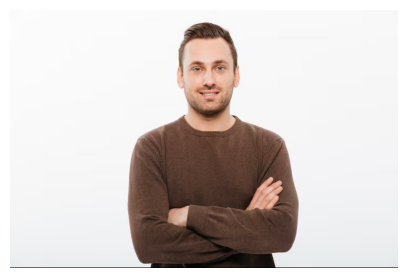

Image size: (740, 493)


In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

image_path = "/content/SAM/test.jpg"

img = Image.open(image_path).convert("RGB")

plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis("off")
plt.show()

print("Image size:", img.size)


In [ ]:
import torch
from torchvision import transforms
from PIL import Image

image_path = "/content/SAM/test.jpg"

transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5],
                         [0.5, 0.5, 0.5])
])

img = Image.open(image_path).convert("RGB")
input_tensor = transform(img).unsqueeze(0).cuda()

print("Input shape:", input_tensor.shape)
print("Device:", input_tensor.device)
print("Minimum:", input_tensor.min().item())
print("Maximum:", input_tensor.max().item())

Input shape: torch.Size([1, 3, 256, 256])
Device: cuda:0
Minimum: -1.0
Maximum: 0.9921568632125854


SAM input shape: torch.Size([1, 4, 256, 256])
Age transformation completed!


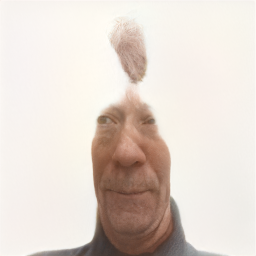

In [ ]:
from datasets.augmentations import AgeTransformer
from utils.common import tensor2im
from PIL import Image
import torch

# Choose target age
target_age = "60"

# Add SAM's age channel
age_transformer = AgeTransformer(target_age=target_age)
input_age = age_transformer(input_tensor[0].cpu())

# Add batch dimension and move to GPU
input_age = input_age.unsqueeze(0).cuda().float()

print("SAM input shape:", input_age.shape)

# Generate aged face
with torch.no_grad():
    result = net(
        input_age,
        randomize_noise=False,
        resize=True
    )

# Convert and save output
output_image = tensor2im(result[0])
output_image.save("/content/SAM/aged_60.jpg")

print("Age transformation completed!")
display(output_image)

In [ ]:
%cd /content/SAM

from scripts.align_all_parallel import align_face

print("SAM face alignment module imported successfully!")

/content/SAM
SAM face alignment module imported successfully!


In [ ]:
%cd /content/SAM

import os

predictor_path = "shape_predictor_68_face_landmarks.dat"

print("Predictor exists:", os.path.exists(predictor_path))
print("File path:", os.path.abspath(predictor_path))


/content/SAM
Predictor exists: False
File path: /content/SAM/shape_predictor_68_face_landmarks.dat


In [ ]:
%cd /content/SAM

!wget -q http://dlib.net/files/shape_predictor_68_face_landmarks.dat.bz2

!bzip2 -d shape_predictor_68_face_landmarks.dat.bz2

/content/SAM


In [ ]:
import os

predictor_path = "/content/SAM/shape_predictor_68_face_landmarks.dat"

print("Predictor exists:", os.path.exists(predictor_path))

if os.path.exists(predictor_path):
    print("File size:", round(os.path.getsize(predictor_path) / (1024 * 1024), 2), "MB")

Predictor exists: True
File size: 95.08 MB


In [ ]:
%cd /content/SAM

from scripts.align_all_parallel import align_face
from PIL import Image
import inspect

print(inspect.signature(align_face))

/content/SAM
(filepath, predictor)


In [ ]:
%cd /content/SAM

from scripts.align_all_parallel import align_face
import dlib
import os
from PIL import Image

# Load the landmark predictor
predictor_path = "/content/SAM/shape_predictor_68_face_landmarks.dat"
predictor = dlib.shape_predictor(predictor_path)

# Align the original image
input_path = "/content/SAM/test.jpg"
aligned_path = "/content/SAM/aligned_face.png"

aligned_image = align_face(input_path, predictor)

print("Alignment result type:", type(aligned_image))

/content/SAM
Alignment result type: <class 'PIL.Image.Image'>


Aligned image saved: /content/SAM/aligned_face.png
Image dimensions: (256, 256)


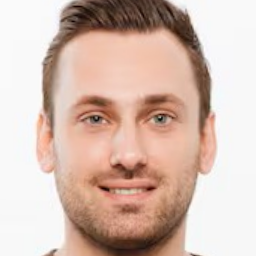

In [ ]:
aligned_path = "/content/SAM/aligned_face.png"

aligned_image.save(aligned_path)

print("Aligned image saved:", aligned_path)
print("Image dimensions:", aligned_image.size)

display(aligned_image)

Aligned age transformation completed!


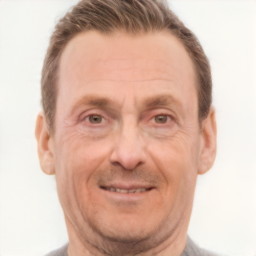

In [ ]:
from PIL import Image
from torchvision import transforms
from datasets.augmentations import AgeTransformer
import torch

# Load aligned face
img = Image.open("/content/SAM/aligned_face.png").convert("RGB")

# Prepare image tensor
transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5],
                         [0.5, 0.5, 0.5])
])

input_tensor = transform(img).unsqueeze(0)

# Add target age channel
age_transformer = AgeTransformer(target_age="60")
input_age = age_transformer(input_tensor[0]).unsqueeze(0).cuda().float()

# Generate aged face
with torch.no_grad():
    result = net(
        input_age,
        randomize_noise=False,
        resize=True
    )

# Save output
from utils.common import tensor2im

output_image = tensor2im(result[0])
output_image.save("/content/SAM/aged_60_aligned.jpg")

print("Aligned age transformation completed!")
display(output_image)

In [ ]:
ages = list(range(0, 101, 10))

for age in ages:
    age_transformer = AgeTransformer(target_age=str(age))

    input_age = age_transformer(
        input_tensor[0]
    ).unsqueeze(0).cuda().float()

    with torch.no_grad():
        result = net(
            input_age,
            randomize_noise=False,
            resize=True
        )

    output_image = tensor2im(result[0])
    output_path = f"/content/SAM/aged_{age}.jpg"
    output_image.save(output_path)

    print(f"Generated age {age}: {output_path}")

print("All 11 age transformations completed!")

Generated age 0: /content/SAM/aged_0.jpg
Generated age 10: /content/SAM/aged_10.jpg
Generated age 20: /content/SAM/aged_20.jpg
Generated age 30: /content/SAM/aged_30.jpg
Generated age 40: /content/SAM/aged_40.jpg
Generated age 50: /content/SAM/aged_50.jpg
Generated age 60: /content/SAM/aged_60.jpg
Generated age 70: /content/SAM/aged_70.jpg
Generated age 80: /content/SAM/aged_80.jpg
Generated age 90: /content/SAM/aged_90.jpg
Generated age 100: /content/SAM/aged_100.jpg
All 11 age transformations completed!


In [ ]:
# Check that SAM and the landmark predictor are still loaded

print("SAM model:", "Ready" if net is not None else "Missing")
print("GPU:", torch.cuda.get_device_name(0))
print("Predictor:", os.path.exists(
    "/content/SAM/shape_predictor_68_face_landmarks.dat"
))

SAM model: Ready
GPU: Tesla T4
Predictor: True


In [ ]:
import os
import io
import secrets
import threading
import tempfile
import zipfile

import torch
from flask import Flask, request, jsonify, send_file
from PIL import Image
from torchvision import transforms

from scripts.align_all_parallel import align_face
from datasets.augmentations import AgeTransformer
from utils.common import tensor2im

# Create API and access key
app = Flask(__name__)
API_KEY = secrets.token_urlsafe(32)
inference_lock = threading.Lock()

# SAM image preprocessing
image_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5],
                         [0.5, 0.5, 0.5])
])

@app.route("/generate", methods=["POST"])
def generate():
    if request.headers.get("Authorization") != f"Bearer {API_KEY}":
        return jsonify({"error": "Unauthorized"}), 401

    if "image" not in request.files:
        return jsonify({"error": "Please upload an image using the 'image' field"}), 400

    uploaded_file = request.files["image"]

    if not uploaded_file.filename:
        return jsonify({"error": "No filename provided"}), 400

    with inference_lock:
        try:
            with tempfile.TemporaryDirectory() as temp_dir:
                input_path = os.path.join(temp_dir, "input.jpg")
                uploaded_file.save(input_path)

                # Official SAM face alignment
                aligned_image = align_face(input_path, predictor)

                # Prepare aligned face
                input_tensor = image_transform(
                    aligned_image.convert("RGB")
                )

                # Generate all 11 ages
                zip_buffer = io.BytesIO()

                with zipfile.ZipFile(
                    zip_buffer, "w", zipfile.ZIP_DEFLATED
                ) as zip_file:

                    for age in range(0, 101, 10):
                        age_transformer = AgeTransformer(
                            target_age=str(age)
                        )

                        input_age = age_transformer(
                            input_tensor
                        ).unsqueeze(0).cuda().float()

                        with torch.no_grad():
                            result = net(
                                input_age,
                                randomize_noise=False,
                                resize=True
                            )

                        output_image = tensor2im(result[0])

                        image_buffer = io.BytesIO()
                        output_image.save(image_buffer, format="JPEG")

                        zip_file.writestr(
                            f"aged_{age}.jpg",
                            image_buffer.getvalue()
                        )

                zip_buffer.seek(0)

                return send_file(
                    zip_buffer,
                    mimetype="application/zip",
                    as_attachment=True,
                    download_name="aged_faces.zip"
                )

        except Exception as error:
            return jsonify({"error": str(error)}), 500

print("Flask API created successfully!")


In [ ]:
import secrets



!pip install pyngrok

In [ ]:
from pyngrok import ngrok

ngrok.set_auth_token("PASTE_YOUR_NGROK_TOKEN")

print("ngrok authentication configured!")

ngrok authentication configured!


In [ ]:
from pyngrok import ngrok
import threading

# Start Flask in a background thread
def run_flask():
    app.run(host="0.0.0.0", port=5000, debug=False, use_reloader=False)

flask_thread = threading.Thread(target=run_flask, daemon=True)
flask_thread.start()

print("Flask server started!")


Flask server started!


In [ ]:
from pyngrok import ngrok

ngrok.kill()



print("ngrok token configured!")

In [ ]:
from pyngrok import ngrok
from pyngrok.conf import PyngrokConfig

ngrok.kill()

config = PyngrokConfig()

print("Previous ngrok process stopped.")

Previous ngrok process stopped.


In [ ]:
public_url = ngrok.connect(5000)

print("Connection successful!")


Connection successful!
Your API is ready.


In [ ]:
import requests

response = requests.get(api_url + "/")


print("Response:", response.text[:300])

INFO:werkzeug:127.0.0.1 - - [31/Oct/2026 06:25:52] "GET / HTTP/1.1" 404 -


HTTP status: 404
Response: <!doctype html>
<html lang=en>
<title>404 Not Found</title>
<h1>Not Found</h1>
<p>The requested URL was not found on the server. If you entered the URL manually please check your spelling and try again.</p>



In [ ]:
import requests

with open("/content/SAM/test.jpg", "rb") as image_file:
    response = requests.post(
        api_url + "/generate",
        headers={
            "Authorization": f"Bearer {API_KEY}"
        },
        files={
            "image": ("test.jpg", image_file, "image/jpeg")
        },
        timeout=600
    )

print("HTTP status:", response.status_code)
print("Content type:", response.headers.get("Content-Type"))

if response.status_code == 200:
    with open("/content/SAM/api_test_results.zip", "wb") as f:
        f.write(response.content)
    print("Success! ZIP file saved.")
else:
    print("API error:", response.text[:1000])

INFO:werkzeug:127.0.0.1 - - [31/Oct/2026 06:26:24] "POST /generate HTTP/1.1" 200 -


HTTP status: 200
Content type: application/zip
Success! ZIP file saved.
